In [8]:

import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Classroom', 'IMG_20201108_201353.JPG', 'Screenshot_20201125_095444.png', 'Screenshot_20201125_105608.png', 'SAMAAS.docx', 'Sample paper 1 std 8.pdf', 'Photo to PDF_2021-02-25_20-21-38.pdf', 'Adobe Scan 09 May 2021.pdf', 'Adobe Scan 27 Jun 2021.pdf', 'https:  story.s.txt', 'Shivansh photo .pdf', 'Untitled folder', 'Shiwangee Rai (1).jpg', 'SECOND PIC.jpg', 'Shiwangee Rai.jpg', 'photo.pdf', 'photo (2).jpg', 'photo (1).jpg', 'photo.jpg', '20250918_215633.jpg', '25E118A05_DS_25E1S3.zip', 'a46486ab-e5fe-4784-bf0a-2207deadb554_copy.pdf', 'Document from Shiwangee✨.pdf', 'JAVA_PART2.gdoc', 'https:  drive.g.txt', 'Colab Notebooks']


In [11]:
!pip install -q kaggle

!kaggle datasets download -d vipoooool/new-plant-diseases-dataset -p /content --unzip

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [02:24<00:00, 20.1MB/s]



In [12]:
import os

print(os.listdir('/content'))

['.config', 'new plant diseases dataset(augmented)', 'test', 'drive', 'New Plant Diseases Dataset(Augmented)', 'sample_data']


In [13]:
import os

for root, dirs, files in os.walk('/content'):
    if 'train' in dirs or 'valid' in dirs:
        print(root)
        print("Folders:", dirs)


/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)
Folders: ['valid', 'train']
/content/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)
Folders: ['valid', 'train']


In [14]:
import os

dataset_path = '/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)'

print("Training folders:", os.listdir(dataset_path + '/train')[:5])
print("Validation folders:", os.listdir(dataset_path + '/valid')[:5])

Training folders: ['Corn_(maize)___Common_rust_', 'Grape___Esca_(Black_Measles)', 'Peach___Bacterial_spot', 'Raspberry___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)']
Validation folders: ['Corn_(maize)___Common_rust_', 'Grape___Esca_(Black_Measles)', 'Peach___Bacterial_spot', 'Raspberry___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)']


In [15]:
import os

print("Current location:", os.getcwd())
print("Model exists:", os.path.exists("trained_model.keras"))

Current location: /content
Model exists: False


In [16]:
from google.colab import files

files.download('trained_model.keras')

FileNotFoundError: Cannot find file: trained_model.keras

## Data Preprocessing

### Training Image Preprocessing

In [17]:
training_set = tf.keras.utils.image_dataset_from_directory(
    '/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)/train',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
)

Found 70295 files belonging to 38 classes.


### Validation Image Preprocessing

In [18]:
import os

print("Current directory:", os.getcwd())
print("Available folders:", os.listdir('/content'))

Current directory: /content
Available folders: ['.config', 'new plant diseases dataset(augmented)', 'test', 'drive', 'New Plant Diseases Dataset(Augmented)', 'sample_data']


In [19]:
os.chdir('/content/new plant diseases dataset(augmented)/New Plant Diseases Dataset(Augmented)')

In [20]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
)

Found 17572 files belonging to 38 classes.


In [21]:
training_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

In [22]:
for x, y in training_set:
    print(x, x.shape)
    print(y, y.shape)
    break

tf.Tensor(
[[[[153.5  142.5  146.5 ]
   [138.75 127.75 131.75]
   [147.5  136.5  140.5 ]
   ...
   [147.25 133.25 133.25]
   [157.75 143.75 143.75]
   [148.25 134.25 134.25]]

  [[156.25 145.25 149.25]
   [147.25 136.25 140.25]
   [135.75 124.75 128.75]
   ...
   [161.25 147.25 147.25]
   [157.5  143.5  143.5 ]
   [147.75 133.75 133.75]]

  [[154.5  143.5  147.5 ]
   [153.25 142.25 146.25]
   [143.5  132.5  136.5 ]
   ...
   [149.   135.   135.  ]
   [167.75 153.75 153.75]
   [159.75 145.75 145.75]]

  ...

  [[158.   148.   156.  ]
   [149.25 139.25 147.25]
   [153.75 143.75 151.75]
   ...
   [155.   146.   149.  ]
   [153.5  144.5  147.5 ]
   [152.75 143.75 146.75]]

  [[152.25 142.25 150.25]
   [149.   139.   147.  ]
   [153.5  143.5  151.5 ]
   ...
   [162.5  153.5  156.5 ]
   [160.75 151.75 154.75]
   [156.75 147.75 150.75]]

  [[153.   143.   151.  ]
   [157.5  147.5  155.5 ]
   [150.25 140.25 148.25]
   ...
   [158.   149.   152.  ]
   [154.   145.   148.  ]
   [154.   145.   14

### To avoid Overshooting
1. Choose small learning rate default 0.001 we are taking 0.0001
2. There may be chance of Underfitting, so increase number of neuron
3. Add more Convolution layer to extract more feature from images there may be possibilty that model unable to capture relevant feature or model is confusing due to lack of feature so feed with more feature

## Building Model

In [23]:
from tensorflow.keras.layers import Dense,Conv2D,MaxPool2D,Flatten,Dropout
from tensorflow.keras.models import Sequential

In [24]:
model = Sequential()

In [25]:
## Building Convolution Layer

In [26]:
model.add(Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
model.add(Conv2D(filters=32,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model.add(Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=64,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [28]:
model.add(Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=128,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [29]:
model.add(Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=256,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [30]:
model.add(Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
model.add(Conv2D(filters=512,kernel_size=3,activation='relu'))
model.add(MaxPool2D(pool_size=2,strides=2))

In [31]:
model.add(Dropout(0.25)) # To avoid Overfitting

In [32]:
model.add(Flatten())

In [33]:
model.add(Dense(units=1500,activation='relu'))

In [34]:
model.add(Dropout(0.4))

In [35]:
#Output Layer
model.add(Dense(units=38,activation='softmax'))

### Compiling Model

In [36]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [37]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        57,038 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,842,762 (29.92 MB)

 Trainable params: 7,842,762 (29.92 MB)

 Non-trainable params: 0 (0.00 B)

### Model Training

In [38]:
import tensorflow as tf

print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [39]:
training_history = model.fit(
    x=training_set,
    validation_data=validation_set,
    epochs=10
)

Epoch 1/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 201s 78ms/step - accuracy: 0.6187 - loss: 1.2934 - val_accuracy: 0.8566 - val_loss: 0.4722
Epoch 2/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 146s 66ms/step - accuracy: 0.8645 - loss: 0.4276 - val_accuracy: 0.9257 - val_loss: 0.2414
Epoch 3/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 145s 66ms/step - accuracy: 0.9140 - loss: 0.2655 - val_accuracy: 0.9322 - val_loss: 0.2047
Epoch 4/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 202s 66ms/step - accuracy: 0.9408 - loss: 0.1802 - val_accuracy: 0.9383 - val_loss: 0.1889
Epoch 5/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 144s 65ms/step - accuracy: 0.9554 - loss: 0.1335 - val_accuracy: 0.9401 - val_loss: 0.1830
Epoch 6/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 145s 66ms/step - accuracy: 0.9666 - loss: 0.1022 - val_accuracy: 0.9605 - val_loss: 0.1251
Epoch 7/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 145s 66ms/step - accuracy: 0.9718 - loss: 0.0842 - val_accuracy: 0.9452 - val_loss: 0.1917
Epoch 8/10
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 154s 70ms/step - accuracy: 

## Model Evaluation

In [40]:
# Model Evaluation on Training set
train_loss, train_acc = model.evaluate(training_set)

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 56s 26ms/step - accuracy: 0.9870 - loss: 0.0388


In [41]:
print(train_loss, train_acc)

0.038801826536655426 0.9870260953903198


In [42]:
#Model on Validation set
val_loss,val_acc = model.evaluate(validation_set)

550/550 ━━━━━━━━━━━━━━━━━━━━ 12s 22ms/step - accuracy: 0.9610 - loss: 0.1388


In [43]:
print(val_loss,val_acc)

0.13877485692501068 0.9609606266021729


### Saving Model

In [44]:
model.save('/content/drive/MyDrive/trained_model.keras')

In [47]:
import os

print(os.path.exists('/content/drive/MyDrive/trained_model.keras'))

True


In [48]:
model.save("trained_model.keras")

In [60]:
training_history.history

{'accuracy': [0.6186784505844116,
  0.8644711375236511,
  0.9140479564666748,
  0.9407639503479004,
  0.9554022550582886,
  0.9666405916213989,
  0.971818745136261,
  0.9755886197090149,
  0.9799274206161499,
  0.9821608662605286],
 'loss': [1.2933686971664429,
  0.4275570213794708,
  0.2655174434185028,
  0.1801605373620987,
  0.13354909420013428,
  0.10220333933830261,
  0.08424718677997589,
  0.07498457282781601,
  0.062008086591959,
  0.054070789366960526],
 'val_accuracy': [0.8566469550132751,
  0.9257341027259827,
  0.9322217106819153,
  0.9383109211921692,
  0.9400750994682312,
  0.9605053663253784,
  0.9451969265937805,
  0.9681311249732971,
  0.9603345990180969,
  0.9609606266021729],
 'val_loss': [0.4722181558609009,
  0.24143168330192566,
  0.20469914376735687,
  0.18893350660800934,
  0.18296633660793304,
  0.12508639693260193,
  0.19168025255203247,
  0.10495494306087494,
  0.13673056662082672,
  0.1387747973203659]}

In [61]:
#Recording History in json
import json
with open("training_hist.json","w") as f:
    json.dump(training_history.history,f)

In [62]:
training_history.history['val_accuracy']

[0.8566469550132751,
 0.9257341027259827,
 0.9322217106819153,
 0.9383109211921692,
 0.9400750994682312,
 0.9605053663253784,
 0.9451969265937805,
 0.9681311249732971,
 0.9603345990180969,
 0.9609606266021729]

In [63]:
import json

with open('/content/drive/MyDrive/training_history.json', 'w') as f:
    json.dump(training_history.history, f, indent=4)

print("JSON file saved successfully!")

JSON file saved successfully!


### Accuracy Visualization

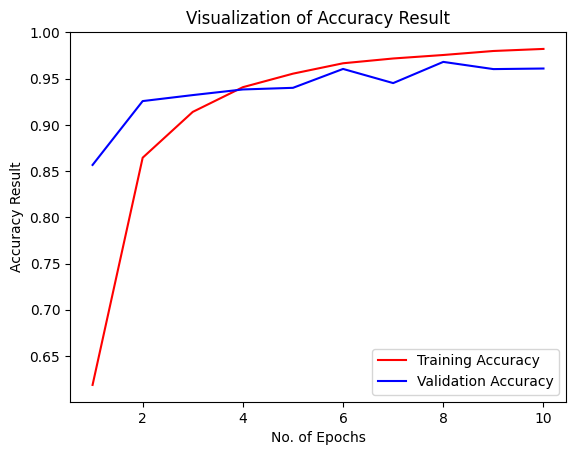

In [52]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='red',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='blue',label='Validation Accuracy')
plt.xlabel("No. of Epochs")
plt.ylabel("Accuracy Result")
plt.title("Visualization of Accuracy Result")
plt.legend()
plt.show()

### Some other metrics for model evaluation

In [53]:
class_name = validation_set.class_names
class_name

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [54]:
test_set = tf.keras.utils.image_dataset_from_directory(
    'valid',
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False,
)

Found 17572 files belonging to 38 classes.


In [55]:
y_pred = model.predict(test_set)
y_pred,y_pred.shape

550/550 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step


(array([[1.00000000e+00, 1.91399385e-09, 2.45175603e-12, ...,
         6.41273424e-19, 1.41038050e-17, 1.61061383e-16],
        [9.99995232e-01, 2.23653888e-06, 1.96290930e-08, ...,
         1.62115319e-12, 1.14211982e-11, 2.62876405e-11],
        [1.00000000e+00, 2.37774905e-14, 8.22023602e-13, ...,
         1.53426623e-20, 4.71863371e-19, 5.41680429e-16],
        ...,
        [1.21004170e-11, 1.54705743e-13, 1.15040553e-10, ...,
         6.13622998e-12, 9.72245808e-12, 1.00000000e+00],
        [5.85468618e-11, 1.24355376e-12, 1.20005561e-10, ...,
         1.94585389e-11, 1.22064747e-10, 9.99999881e-01],
        [1.00843539e-15, 6.65637450e-18, 1.37808303e-16, ...,
         1.10964658e-16, 2.73549900e-14, 1.00000000e+00]],
       shape=(17572, 38), dtype=float32),
 (17572, 38))

In [ ]:
predicted_categories = tf.argmax(y_pred,axis=1)

In [ ]:
predicted_categories

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], shape=(17572,))>

In [ ]:
true_categories = tf.concat([y for x,y in test_set],axis=0)
true_categories

<tf.Tensor: shape=(17572, 38), dtype=float32, numpy=
array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.]], shape=(17572, 38), dtype=float32)>

In [ ]:
Y_true = tf.argmax(true_categories,axis=1)
Y_true

<tf.Tensor: shape=(17572,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], shape=(17572,))>

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
print(classification_report(Y_true,predicted_categories,target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.94      0.99      0.96       504
                                 Apple___Black_rot       1.00      0.96      0.98       497
                          Apple___Cedar_apple_rust       0.99      0.98      0.99       440
                                   Apple___healthy       0.95      0.98      0.96       502
                               Blueberry___healthy       0.97      0.98      0.97       454
          Cherry_(including_sour)___Powdery_mildew       0.97      0.99      0.98       421
                 Cherry_(including_sour)___healthy       0.98      0.99      0.99       456
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.91      0.97      0.94       410
                       Corn_(maize)___Common_rust_       1.00      0.99      0.99       477
               Corn_(maize)___Northern_Leaf_Blight       0.98      0.94      0.

In [ ]:
cm = confusion_matrix(Y_true,predicted_categories)
cm

array([[498,   0,   0, ...,   0,   0,   0],
       [  0, 476,   0, ...,   0,   0,   0],
       [  1,   0, 433, ...,   0,   0,   0],
       ...,
       [  0,   0,   0, ..., 487,   0,   0],
       [  0,   0,   0, ...,   0, 444,   0],
       [  0,   0,   0, ...,   0,   0, 472]], shape=(38, 38))

### Confusion Matrix Visualization

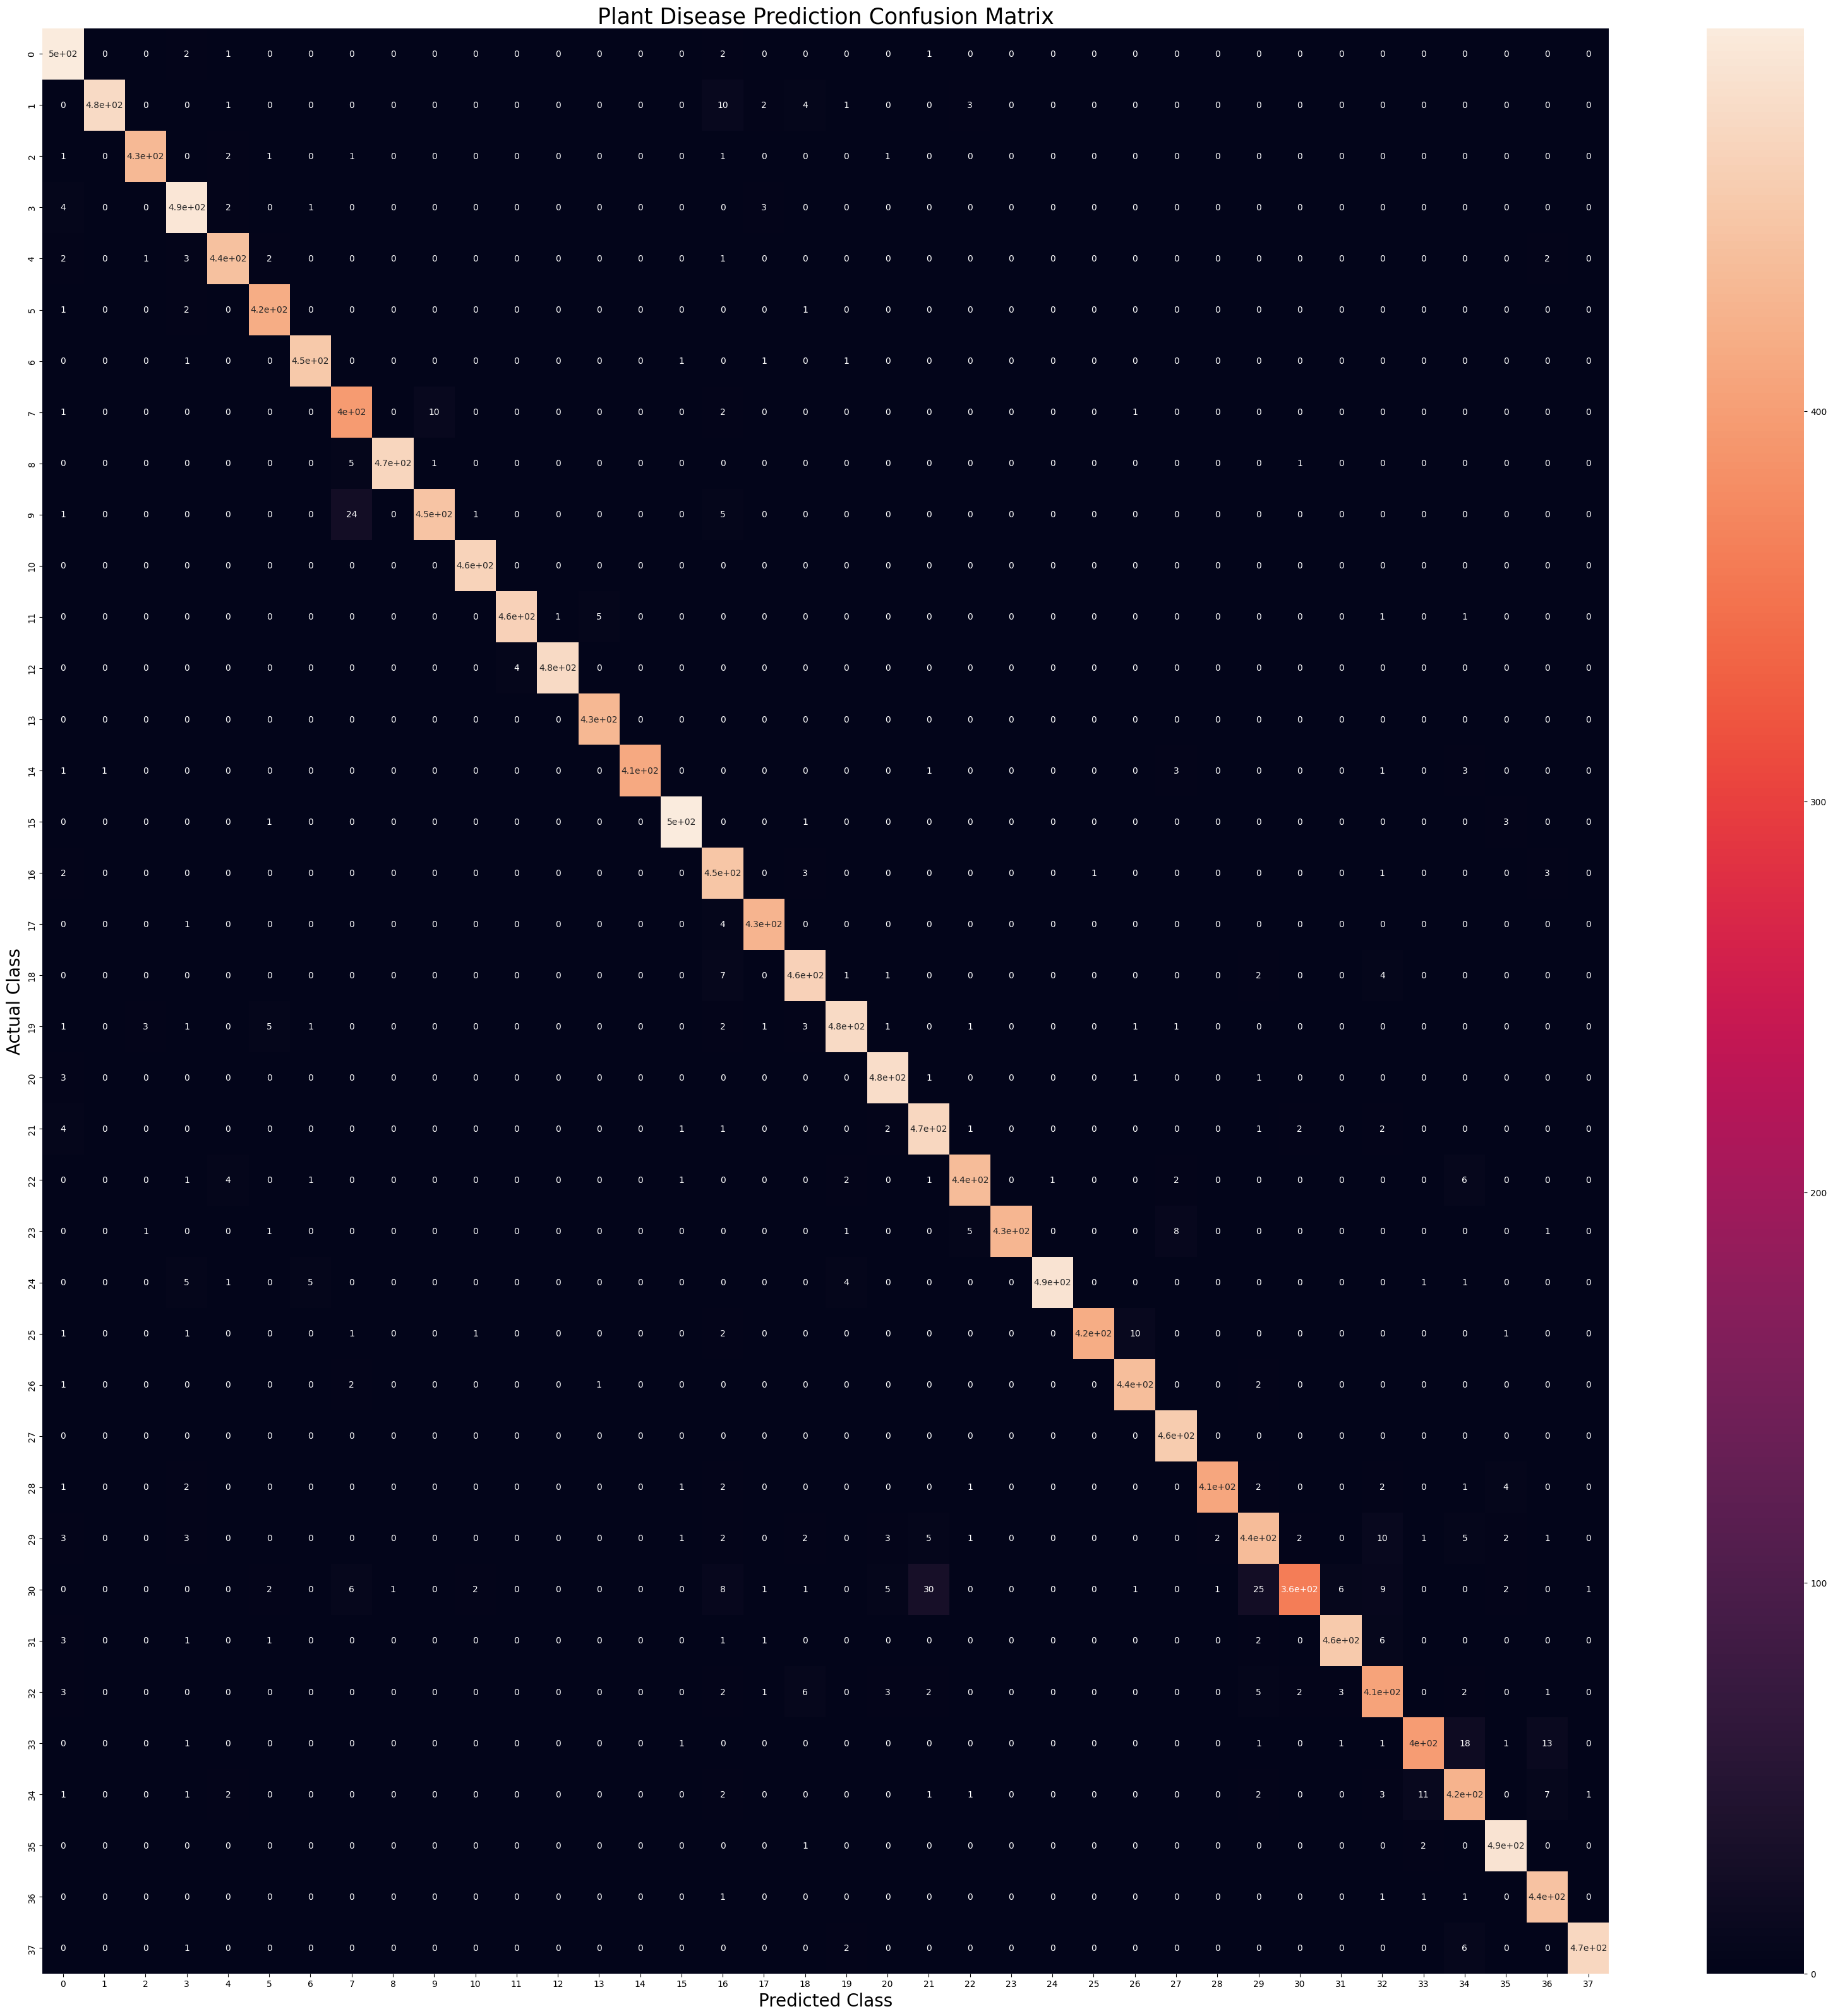

In [ ]:
plt.figure(figsize=(40,40))
sns.heatmap(cm,annot=True,annot_kws={'size':10})
plt.xlabel("Predicted Class",fontsize=20)
plt.ylabel("Actual Class",fontsize=20)
plt.title("Plant Disease Prediction Confusion Matrix",fontsize=25)
plt.show()